In [3]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

root = '/Users/samsonkoelle/isometry-pursuit'

with open(f'{root}/results/ethanol_results.json') as f:
    results = json.load(f)

with open(f'{root}/data/ethanol_metadata.json') as f:
    meta = json.load(f)

replicates_df = pd.DataFrame(results['replicates'])
selected_points = np.array(meta['selected_points'])
angles = np.load(f'{root}/{meta["angles_file"]}')

replicates_df.head()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,replicate,support_cardinality,isometry_loss,group_lasso_norm,basis_pursuit_iterations,basis_pursuit_indices
0,0,3,2.127095,2.195473,750,"[103, 151, 403]"
1,1,2,2.112337,2.112904,1000,"[79, 602]"
2,2,3,2.051222,2.279705,525,"[13, 175, 403]"
3,3,3,2.070382,2.289941,850,"[13, 103, 653]"
4,4,3,2.717013,3.623134,625,"[73, 253, 601]"


In [4]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

root = '/Users/samsonkoelle/isometry-pursuit'

with open(f'{root}/results/ethanol_results.json') as f:
    results = json.load(f)

with open(f'{root}/data/ethanol_metadata.json') as f:
    meta = json.load(f)

replicates_df = pd.DataFrame(results['replicates'])
selected_points = np.array(meta['selected_points'])
angles = np.load(f'{root}/{meta["angles_file"]}')

replicates_df.head()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,replicate,support_cardinality,isometry_loss,group_lasso_norm,basis_pursuit_iterations,basis_pursuit_indices
0,0,3,2.127095,2.195287,100000,"[103, 151, 403]"
1,1,310,88.309620,2.279972,100000,"[12, 14, 15, 18, 19, 20, 21, 22, 24, 26, 27, 3..."
2,2,3,2.051222,2.279704,100000,"[13, 175, 403]"
3,3,3,2.070382,2.294742,100000,"[13, 103, 653]"
4,4,3,2.717013,3.621713,100000,"[73, 253, 601]"


NameError: name 'X_t' is not defined

In [2]:
replicates_df.describe()

,replicate,support_cardinality,isometry_loss,group_lasso_norm,basis_pursuit_iterations
count,5.000000,5.000000,5.000000,5.000000,5.0
mean,2.000000,64.400000,19.455066,2.534284,100000.0
std,1.581139,137.294574,38.491855,0.609157,0.0
min,0.000000,3.000000,2.051222,2.195287,100000.0
25%,1.000000,3.000000,2.070382,2.279704,100000.0
50%,2.000000,3.000000,2.127095,2.279972,100000.0
75%,3.000000,3.000000,2.717013,2.294742,100000.0
max,4.000000,310.000000,88.309620,3.621713,100000.0


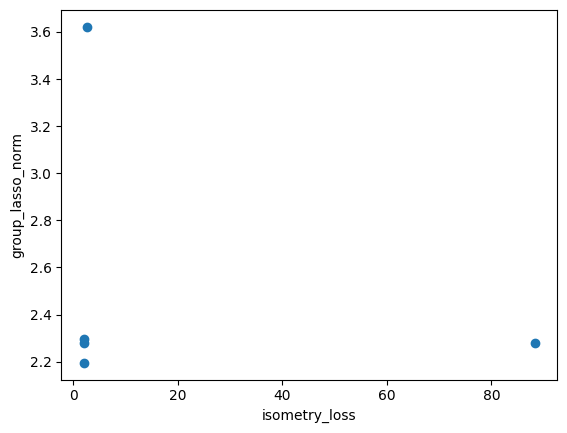

In [3]:
fig, ax = plt.subplots()
ax.scatter(replicates_df['isometry_loss'], replicates_df['group_lasso_norm'])
ax.set_xlabel('isometry_loss')
ax.set_ylabel('group_lasso_norm')
plt.show()

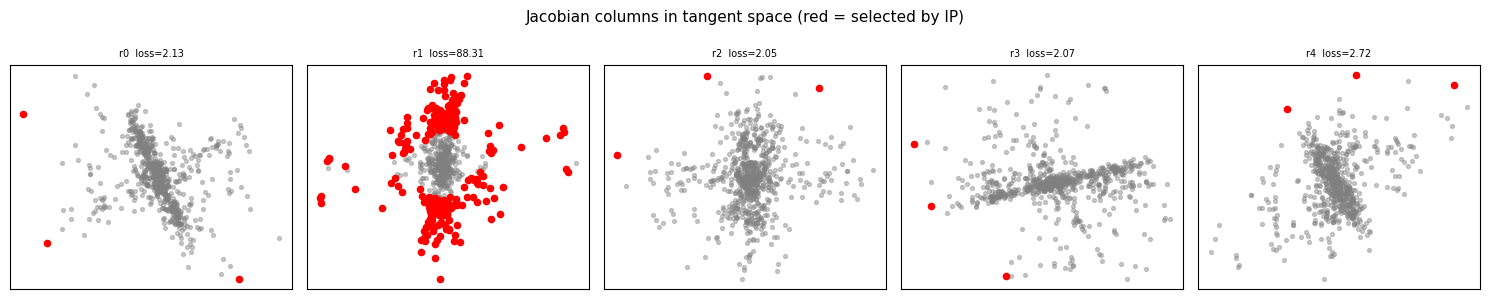

In [4]:
data_tensor = np.load('/Users/samsonkoelle/isometry-pursuit/data/ethanol_tensor.npy')  # (2, p, R)
R = data_tensor.shape[2]
losses = replicates_df['isometry_loss'].values
all_indices = replicates_df['basis_pursuit_indices'].tolist()

ncols = 5
nrows = (R + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
axes = axes.flatten()

for i in range(R):
    ax = axes[i]
    cols = data_tensor[:, :, i]  # (2, p)
    selected = all_indices[i]
    mask = np.zeros(cols.shape[1], dtype=bool)
    mask[selected] = True

    ax.scatter(cols[0, ~mask], cols[1, ~mask], s=8, alpha=0.4, color='gray', label='other')
    ax.scatter(cols[0, mask], cols[1, mask], s=20, color='red', label='selected')
    ax.set_title(f'r{i}  loss={losses[i]:.2f}', fontsize=7)
    ax.set_xticks([])
    ax.set_yticks([])

for i in range(R, len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Jacobian columns in tangent space (red = selected by IP)', fontsize=11)
plt.tight_layout()
plt.show()

In [5]:
import os
os.getcwd()

'/Users/samsonkoelle/isometry-pursuit/experiments'

In [14]:
import sys
# !{sys.executable} -m pip install -e /Users/samsonkoelle/isometry-pursuit
from isometry_pursuit.algorithm import isometry_pursuit
from isometry_pursuit.loss import isometry_loss

r = 1
X = data_tensor[:, :756, r]  # (2, p)
print(X.shape)
result = isometry_pursuit(X)
indices = result['basis_pursuit_indices']
print(indices)
# stored = replicates_df.iloc[r]
# print(f'stored  indices: {stored["basis_pursuit_indices"]}')
# print(f'reproduced indices: {indices.tolist()}')
# print(f'stored  isometry_loss: {stored["isometry_loss"]:.6f}')
# print(f'reproduced isometry_loss: {isometry_loss(X[:, indices]):.6f}')
# print(f'stored  support_cardinality: {stored["support_cardinality"]}')
# print(f'reproduced support_cardinality: {len(indices)}')

(2, 756)
obv 2.1129039546767086
[ 79 602]


In [50]:
from isometry_pursuit.loss import group_lasso_norm

glnorm = group_lasso_norm(result['beta'])


In [51]:
glnorm

2.2799718406967626

In [48]:
glnorm

2.1129039258663687

In [32]:
??isometry_pursuit

Signature:
isometry_pursuit(
    X,
    power=1.0,
    limit=1000000.0,
    max_steps=None,
    log_convergence=False,
    constraint_violation=0.0,
)
Docstring: <no docstring>
Source:   
def isometry_pursuit(
    X,
    power=1.0,
    limit=1e6,
    max_steps=None,
    log_convergence=False,
    constraint_violation=0.0,
):
    D, P = X.shape
    data_transformed = exponential_transformation(X, power=power)
    # Use CVXPY implementation
    beta, basis_pursuit_iterations, objective_value = group_basis_pursuit(
        data_transformed, constraint_violation=constraint_violation
    )
    # Note: Convergence logging is not implemented for the main experiment flow
    # since it would require calling group_basis_pursuit multiple times with different parameters
    # For convergence analysis, use the standalone convergence logging functions
    basis_pursuit_indices = np.where(np.linalg.norm(beta, axis=1) > THRESHOLD)[0]

    return {
        "beta": beta,
        "basis_pursuit_indices"

In [9]:
r = 1
X = data_tensor[:, :, r]  # (2, p)
p = X.shape[1]
print(f'Replicate {r}: p={p}, stored support={replicates_df.iloc[r]["support_cardinality"]}')
print()

factors = [1, 2, 4, 8, 16, 32]
for factor in factors:
    n_cols = p // factor
    col_idx = np.linspace(0, p - 1, n_cols, dtype=int)
    X_sub = X[:, col_idx]
    result = isometry_pursuit.algorithm.isometry_pursuit(X_sub)
    idx = result['basis_pursuit_indices']
    loss = isometry_loss(X_sub[:, idx]) if len(idx) > 0 else float('inf')
    print(f'factor={factor:3d}  n_cols={n_cols:5d}  support={len(idx):5d}  loss={loss:.4f}')

Replicate 1: p=756, stored support=310



/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  1  n_cols=  756  support=  310  loss=88.3096


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  2  n_cols=  378  support=    2  loss=2.3395


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  4  n_cols=  189  support=    2  loss=2.4961


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


factor=  8  n_cols=   94  support=    2  loss=2.5168
factor= 16  n_cols=   47  support=    2  loss=3.0669
factor= 32  n_cols=   23  support=    3  loss=2.7349


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


In [11]:
import numpy as np
from isometry_pursuit.algorithm import isometry_pursuit
from isometry_pursuit.loss import isometry_loss

r = 1
X = data_tensor[:, :, r]
p = X.shape[1]
factors = [2]
n_random_reps = 10
rng = np.random.default_rng(42)

print(f"{'factor':>8} {'n_cols':>8} {'support_mean':>14} {'support_std':>12} {'loss_mean':>12} {'loss_std':>10}")
for factor in factors:
    n_cols = p // factor
    supports, losses = [], []
    for _ in range(n_random_reps):
        col_idx = rng.choice(p, size=n_cols, replace=False)
        X_sub = X[:, col_idx]
        result = isometry_pursuit(X_sub)
        idx = result['basis_pursuit_indices']
        loss = isometry_loss(X_sub[:, idx]) if len(idx) > 0 else float('inf')
        supports.append(len(idx))
        losses.append(loss)
    print(f"{factor:>8} {n_cols:>8} {np.mean(supports):>14.1f} {np.std(supports):>12.1f} {np.mean(losses):>12.4f} {np.std(losses):>10.4f}")


  factor   n_cols   support_mean  support_std    loss_mean   loss_std


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting

       2      378            2.2          0.4       2.1631     0.0804


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


In [12]:
losses

[2.349553473818398,
 2.1123366162604196,
 2.2250337405714653,
 2.1123366162604196,
 2.114598126657492,
 2.114598126657492,
 2.114598126657492,
 2.114598126657492,
 2.114598126657492,
 2.25886634916421]

In [7]:
import isometry_pursuit

In [2]:
import os
os.chdir('/Users/samsonkoelle')

In [16]:
import numpy as np
from isometry_pursuit.algorithm import isometry_pursuit
from isometry_pursuit.loss import isometry_loss

r = 1
X = data_tensor[:, :, r]
p = X.shape[1]  # 756
rng = np.random.default_rng(42)
n_random_reps = 1

sizes = [756]
# sizes = list(range(756, 328 - 1, -20))  # 756, 736, 716, ..., 336
results = []

for n_cols in sizes:
    for rep in range(n_random_reps):
        col_idx = rng.choice(p, size=n_cols, replace=False)
        X_sub = X[:, col_idx]
        res = isometry_pursuit(X_sub)
        idx = res['basis_pursuit_indices']
        loss = isometry_loss(X_sub[:, idx]) if len(idx) > 0 else float('inf')
        results.append({'n_cols': n_cols, 'rep': rep, 'support': len(idx), 'loss': loss})
    print(f"n_cols={n_cols}  mean_support={np.mean([r['support'] for r in results if r['n_cols']==n_cols]):.1f}")


n_cols=756  mean_support=2.0


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame(results)
grouped = df.groupby('n_cols')['support']

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(grouped.mean().index, grouped.mean().values, 'o-')
ax.fill_between(grouped.mean().index,
                grouped.mean() - grouped.std(),
                grouped.mean() + grouped.std(), alpha=0.3)
ax.set_xlabel('n_cols (features)')
ax.set_ylabel('support cardinality')
ax.invert_xaxis()
plt.tight_layout()
plt.show()
